# CalificacionDemanda — Cuaderno experimental de tesis

**Título propuesto:** Proyección de Auto de Calificación de Demandas en la especialidad y subespecialidad de Familia Civil en Materia de Alimentos.

Este notebook documenta resultados reproducibles a partir de archivos **locales**. No publica expedientes ni datos personales. La matriz de consistencia se mantiene en el `README.md`. **No ejecuta automáticamente scripts que modifican datos.**

## 1. Configuración y comprobación del entorno

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

# Permite ejecutar desde la raíz del repositorio o desde notebooks/
actual = Path.cwd().resolve()
ROOT = actual if (actual / 'src').is_dir() else actual.parent
assert (ROOT / 'src').is_dir(), f"No se encontró src/ en {ROOT}. Abre VS Code en D:\\CalificacionDemanda"
PROCESSED = ROOT / 'data' / 'processed'
print('Proyecto:', ROOT)
print('Python:', sys.executable)
print('Datos procesados:', PROCESSED.exists())

Proyecto: D:\CalificacionDemanda
Python: d:\CalificacionDemanda\.venv\Scripts\python.exe
Datos procesados: True


## 2. Inventario de archivos procesados

In [2]:
archivos = sorted(PROCESSED.glob('*.csv')) if PROCESSED.exists() else []
print(f'Archivos CSV locales: {len(archivos)}')
pd.DataFrame({'archivo': [p.name for p in archivos], 'bytes': [p.stat().st_size for p in archivos]})

Archivos CSV locales: 28


,archivo,bytes
0,auditoria_autos.csv,1922
1,caracteristicas_demandas.csv,479
2,dataset_casos.csv,1078
3,dataset_consolidado.csv,2363
4,dataset_entrenamiento.csv,831
5,dataset_textos_demandas.csv,28115
6,dataset_textos_ocr.csv,36390
7,diagnostico_pdf.csv,831
8,estructura_autos.csv,453
9,etiquetas_revision.csv,10168


## 3. Dataset de casos y validación jurídica

In [3]:
def cargar_csv(nombre):
    ruta = PROCESSED / nombre
    if not ruta.exists():
        print(f'Pendiente: {ruta.name} no existe. Ejecuta primero el script correspondiente.')
        return pd.DataFrame()
    try:
        df = pd.read_csv(ruta, encoding='utf-8-sig')
    except UnicodeDecodeError:
        df = pd.read_csv(ruta, encoding='latin-1')
    print(f'{nombre}: {len(df)} filas, {len(df.columns)} columnas')
    return df

validacion = cargar_csv('validacion_juridica.csv')
print('Columnas:', validacion.columns.tolist())

validacion_juridica.csv: 11 filas, 13 columnas
Columnas: ['caso_id', 'auto', 'palabras_clave', 'materia_validada', 'tipo_procedimiento', 'objeto_decision', 'decision_principal', 'etiqueta_validada', 'pagina_evidencia', 'observaciones', 'revisor', 'estado_revision', 'decision_asignacion_anticipada']


**Control de calidad:** identificar la columna de decisión validada antes de calcular la distribución. No usar decisiones extraídas automáticamente como etiquetas definitivas sin revisión jurídica.

,calificación,casos
0,ADMISIBLE,9
1,FUERA_ALCANCE,1
2,INADMISIBLE,1


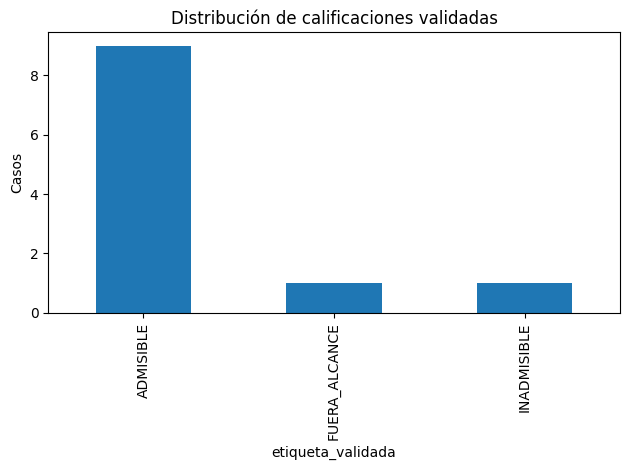

In [4]:
# Ajustar únicamente después de verificar los nombres de columnas del CSV.
candidatas = ['decision_validada', 'calificacion_validada', 'etiqueta_validada', 'decision_final_validada']
columna = next((c for c in candidatas if c in validacion.columns), None)
if columna:
    conteo = validacion[columna].fillna('SIN_ETIQUETA').value_counts()
    display(conteo.rename_axis('calificación').reset_index(name='casos'))
    conteo.plot.bar(title='Distribución de calificaciones validadas', ylabel='Casos')
    plt.tight_layout()
    plt.show()
else:
    print('Revisar columnas y seleccionar manualmente la etiqueta validada. No se infiere automáticamente.')

## 4. Inventario documental y clasificación de páginas

In [5]:
paginas = cargar_csv('inventario_paginas.csv')
if not paginas.empty:
    display(paginas.head(5))
    if 'caso_id' in paginas:
        display(paginas.groupby('caso_id').size().rename('paginas').reset_index())
    if 'tipo_contenido' in paginas:
        display(paginas['tipo_contenido'].fillna('SIN_CLASIFICAR').value_counts().head(20))

inventario_paginas.csv: 141 filas, 11 columnas


,caso_id,documento,pagina,tiene_texto_digital,caracteres_digitales,imagenes_incrustadas,tipo_contenido,contiene_datos_personales,incluir_entrenamiento,estado_revision,observaciones
0,CASO_001,caso_001\demanda_1.pdf,1,SI,262,1,CARGO_INGRESO,SI,SI,VALIDADO,CARGO DE INGRESO DE EXPEDIENTE
1,CASO_001,caso_001\demanda_1.pdf,2,NO,0,1,CARATULA_EXPEDIENTE,SI,SI,VALIDADO,NINGUNA
2,CASO_001,caso_001\demanda_1.pdf,3,NO,0,1,DEMANDA,SI,SI,VALIDADO,NaN
3,CASO_001,caso_001\demanda_1.pdf,4,NO,0,1,NaN,PENDIENTE,PENDIENTE,PENDIENTE,NaN
4,CASO_001,caso_001\demanda_1.pdf,5,NO,0,1,NaN,PENDIENTE,PENDIENTE,PENDIENTE,NaN


,caso_id,paginas
0,CASO_001,13
1,CASO_002,23
2,CASO_004,8
3,CASO_005,6
4,CASO_006,9
5,CASO_007,10
6,CASO_008,10
7,CASO_009,11
8,CASO_010,11
9,CASO_011,40


tipo_contenido
SIN_CLASIFICAR         138
CARGO_INGRESO            1
CARATULA_EXPEDIENTE      1
DEMANDA                  1
Name: count, dtype: int64

## 5. Extracción de texto y OCR

Scripts relacionados (ejecutarlos **por separado** cuando corresponda):

- `src/diagnosticar_pdf.py`
- `src/extraer_texto_demandas.py`
- `src/ocr_demandas.py`
- `src/clasificar_paginas.py`

No basta con detectar texto OCR: una página puede contener DNI, boletas, imágenes o varios tipos de anexos. La revisión documental debe preceder a la extracción de características.

In [6]:
reporte_ocr = cargar_csv('reporte_ocr.csv')
if not reporte_ocr.empty:
    print('Columnas OCR:', reporte_ocr.columns.tolist())
    display(reporte_ocr.head(5))

reporte_ocr.csv: 10 filas, 8 columnas
Columnas OCR: ['caso_id', 'documentos_esperados', 'documentos_procesados', 'paginas', 'paginas_ocr', 'paginas_sin_resultado', 'estado', 'errores']


,caso_id,documentos_esperados,documentos_procesados,paginas,paginas_ocr,paginas_sin_resultado,estado,errores
0,CASO_001,1,1,13,12,1,REVISAR,NaN
1,CASO_002,1,1,23,22,2,REVISAR,NaN
2,CASO_004,1,1,8,0,0,OK,NaN
3,CASO_005,1,1,6,5,2,REVISAR,NaN
4,CASO_006,1,1,9,0,0,OK,NaN


## 6. Análisis exploratorio de datos (EDA)

In [7]:
dataset = cargar_csv('dataset_entrenamiento.csv')
if not dataset.empty:
    print('Dimensiones:', dataset.shape)
    display(dataset.isna().sum().sort_values(ascending=False).head(15).rename('faltantes'))
    # Mostrar nombres de columnas en lugar de textos de demandas o datos personales
    print('Columnas disponibles:', dataset.columns.tolist())

dataset_entrenamiento.csv: 10 filas, 5 columnas
Dimensiones: (10, 5)


documentos_complementarios    8
caso_id                       0
demanda_principal             0
estado                        0
etiqueta_validada             0
Name: faltantes, dtype: int64

Columnas disponibles: ['caso_id', 'demanda_principal', 'documentos_complementarios', 'estado', 'etiqueta_validada']


## agregamos celda para cargar dataset de entrenamiento

In [8]:
from pathlib import Path
import pandas as pd

ruta = Path.cwd()

if ruta.name.lower() == "notebooks":
    ruta = ruta.parent

archivo = ruta / "data" / "processed" / "dataset_entrenamiento.csv"

df = pd.read_csv(archivo)

print("Cantidad de registros:", len(df))
print("Columnas disponibles:")
print(df.columns.tolist())

display(df.head())

Cantidad de registros: 10
Columnas disponibles:
['caso_id', 'demanda_principal', 'documentos_complementarios', 'estado', 'etiqueta_validada']


,caso_id,demanda_principal,documentos_complementarios,estado,etiqueta_validada
0,CASO_001,caso_001\demanda_1.pdf,NaN,pendiente_verificacion,ADMISIBLE
1,CASO_002,caso_002\demanda_2.pdf,NaN,pendiente_verificacion,ADMISIBLE
2,CASO_004,caso_004\demanda_4.pdf,NaN,pendiente_verificacion,ADMISIBLE
3,CASO_005,caso_005\demanda_5.pdf,NaN,pendiente_verificacion,INADMISIBLE
4,CASO_006,caso_006\demanda_6.pdf,NaN,pendiente_verificacion,ADMISIBLE


In [9]:
print(df.info())

print("\nValores faltantes:")
display(df.isna().sum().sort_values(ascending=False))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   caso_id                     10 non-null     object
 1   demanda_principal           10 non-null     object
 2   documentos_complementarios  2 non-null      object
 3   estado                      10 non-null     object
 4   etiqueta_validada           10 non-null     object
dtypes: object(5)
memory usage: 528.0+ bytes
None

Valores faltantes:


documentos_complementarios    8
caso_id                       0
demanda_principal             0
estado                        0
etiqueta_validada             0
dtype: int64

## Comprobación de acceso a PDF ##

In [10]:
from pathlib import Path
import pandas as pd
import pymupdf

BASE = Path.cwd().resolve()

if BASE.name.lower() == "notebooks":
    BASE = BASE.parent

DATASET = BASE / "data" / "processed" / "dataset_entrenamiento.csv"
RAW = BASE / "data" / "raw"

df = pd.read_csv(DATASET)

def localizar_pdf(ruta_relativa):
    if pd.isna(ruta_relativa):
        return None

    ruta = Path(str(ruta_relativa).replace("\\", "/"))

    candidatos = [
        RAW / ruta,
        RAW / "documento" / ruta,
        BASE / ruta
    ]

    for candidato in candidatos:
        if candidato.is_file():
            return candidato

    return None

df["ruta_pdf"] = df["demanda_principal"].apply(localizar_pdf)

print("Casos:", len(df))
print("PDF encontrados:", df["ruta_pdf"].notna().sum())
print("PDF no encontrados:", df["ruta_pdf"].isna().sum())

display(df[["caso_id", "demanda_principal", "ruta_pdf"]])

Casos: 10
PDF encontrados: 10
PDF no encontrados: 0


,caso_id,demanda_principal,ruta_pdf
0,CASO_001,caso_001\demanda_1.pdf,D:\CalificacionDemanda\data\raw\caso_001\deman...
1,CASO_002,caso_002\demanda_2.pdf,D:\CalificacionDemanda\data\raw\caso_002\deman...
2,CASO_004,caso_004\demanda_4.pdf,D:\CalificacionDemanda\data\raw\caso_004\deman...
3,CASO_005,caso_005\demanda_5.pdf,D:\CalificacionDemanda\data\raw\caso_005\deman...
4,CASO_006,caso_006\demanda_6.pdf,D:\CalificacionDemanda\data\raw\caso_006\deman...
5,CASO_007,caso_007\demanda_7.pdf,D:\CalificacionDemanda\data\raw\caso_007\deman...
6,CASO_008,caso_008\demanda_8.pdf,D:\CalificacionDemanda\data\raw\caso_008\deman...
7,CASO_009,caso_009\demanda_9.pdf,D:\CalificacionDemanda\data\raw\caso_009\deman...
8,CASO_010,caso_010\demanda_10.pdf,D:\CalificacionDemanda\data\raw\caso_010\deman...
9,CASO_011,caso_011\demanda_11.pdf,D:\CalificacionDemanda\data\raw\caso_011\deman...


##Extraer caracteristicas de documentos incial##

In [11]:
import re

def extraer_caracteristicas(fila):
    ruta = fila["ruta_pdf"]

    resultado = {
        "caso_id": fila["caso_id"],
        "etiqueta_validada": fila["etiqueta_validada"],
        "numero_paginas": 0,
        "caracteres_texto": 0,
        "tiene_petitorio": 0,
        "tiene_fundamentos_hecho": 0,
        "tiene_fundamentos_derecho": 0,
        "menciona_medios_probatorios": 0,
        "menciona_acta_nacimiento": 0,
        "requiere_ocr": 0,
    }

    if ruta is None:
        return resultado

    with pymupdf.open(ruta) as pdf:
        paginas = [pagina.get_text("text") for pagina in pdf]

    texto = "\n".join(paginas).lower()

    resultado["numero_paginas"] = len(paginas)
    resultado["caracteres_texto"] = len(texto)

    resultado["tiene_petitorio"] = int(
        bool(re.search(r"\bpetitorio\b", texto))
    )

    resultado["tiene_fundamentos_hecho"] = int(
        bool(re.search(r"fundamentos?\s+de\s+hecho", texto))
    )

    resultado["tiene_fundamentos_derecho"] = int(
        bool(re.search(r"fundamentos?\s+de\s+derecho", texto))
    )

    resultado["menciona_medios_probatorios"] = int(
        bool(re.search(r"medios?\s+probatorios?", texto))
    )

    resultado["menciona_acta_nacimiento"] = int(
        bool(re.search(r"acta\s+de\s+nacimiento", texto))
    )

    resultado["requiere_ocr"] = int(
        any(len(p.strip()) < 30 for p in paginas)
    )

    return resultado

caracteristicas = pd.DataFrame(
    [extraer_caracteristicas(fila) for _, fila in df.iterrows()]
)

display(caracteristicas)

,caso_id,etiqueta_validada,numero_paginas,caracteres_texto,tiene_petitorio,tiene_fundamentos_hecho,tiene_fundamentos_derecho,menciona_medios_probatorios,menciona_acta_nacimiento,requiere_ocr
0,CASO_001,ADMISIBLE,13,275,0,0,0,0,0,1
1,CASO_002,ADMISIBLE,23,322,0,0,0,0,0,1
2,CASO_004,ADMISIBLE,8,7313,1,0,0,1,1,0
3,CASO_005,INADMISIBLE,6,305,0,0,0,0,0,1
4,CASO_006,ADMISIBLE,9,10066,1,1,0,1,1,0
5,CASO_007,ADMISIBLE,10,276,0,0,0,0,0,1
6,CASO_008,ADMISIBLE,10,10568,1,1,0,1,1,1
7,CASO_009,ADMISIBLE,10,8940,1,1,0,1,1,1
8,CASO_010,ADMISIBLE,4,3,0,0,0,0,0,1
9,CASO_011,ADMISIBLE,40,55934,1,1,0,1,1,1


## Agregar celda ##

In [12]:
SALIDA = BASE / "data" / "processed" / "caracteristicas_demandas.csv"

caracteristicas.to_csv(
    SALIDA,
    index=False,
    encoding="utf-8-sig"
)

print("Características guardadas en:", SALIDA)
print("Dimensiones:", caracteristicas.shape)

Características guardadas en: D:\CalificacionDemanda\data\processed\caracteristicas_demandas.csv
Dimensiones: (10, 10)


##  verificar PDF ##

In [13]:
from pathlib import Path
import pandas as pd

BASE = Path.cwd().resolve()

if BASE.name.lower() == "notebooks":
    BASE = BASE.parent

RAW = BASE / "data" / "raw"

def localizar_pdf(ruta):
    if pd.isna(ruta):
        return None

    relativa = Path(str(ruta).replace("\\", "/"))

    candidatos = [
        RAW / relativa,
        RAW / "documento" / relativa,
        BASE / relativa
    ]

    for archivo in candidatos:
        if archivo.is_file():
            return archivo

    return None

df["ruta_pdf"] = df["demanda_principal"].apply(localizar_pdf)

df["pdf_encontrado"] = df["ruta_pdf"].notna()

print("Total de casos:", len(df))
print("PDF encontrados:", df["pdf_encontrado"].sum())
print("PDF pendientes:", (~df["pdf_encontrado"]).sum())

display(df[["caso_id", "demanda_principal", "pdf_encontrado"]])

Total de casos: 10
PDF encontrados: 10
PDF pendientes: 0


,caso_id,demanda_principal,pdf_encontrado
0,CASO_001,caso_001\demanda_1.pdf,True
1,CASO_002,caso_002\demanda_2.pdf,True
2,CASO_004,caso_004\demanda_4.pdf,True
3,CASO_005,caso_005\demanda_5.pdf,True
4,CASO_006,caso_006\demanda_6.pdf,True
5,CASO_007,caso_007\demanda_7.pdf,True
6,CASO_008,caso_008\demanda_8.pdf,True
7,CASO_009,caso_009\demanda_9.pdf,True
8,CASO_010,caso_010\demanda_10.pdf,True
9,CASO_011,caso_011\demanda_11.pdf,True


## Agregar celda de extraccion ##

In [14]:
import re
import unicodedata
import pandas as pd
import pymupdf

def normalizar_texto(texto):
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(
        c for c in texto
        if not unicodedata.combining(c)
    )
    return re.sub(r"\s+", " ", texto.lower())

def extraer_caracteristicas(fila):
    ruta = fila["ruta_pdf"]

    with pymupdf.open(ruta) as pdf:
        paginas = [
            pagina.get_text("text")
            for pagina in pdf
        ]

    texto = normalizar_texto(" ".join(paginas))

    patrones = {
        "tiene_petitorio": r"\bpetitorio\b",
        "tiene_fundamentos_hecho": r"fundamentos?\s+de\s+hecho",
        "tiene_fundamentos_derecho": r"fundamentos?\s+de\s+derecho",
        "menciona_medios_probatorios": r"medios?\s+probatorios?",
        "menciona_acta_nacimiento": r"acta\s+de\s+nacimiento",
    }

    resultado = {
        "caso_id": fila["caso_id"],
        "numero_paginas": len(paginas),
        "paginas_sin_texto": sum(
            len(p.strip()) < 30 for p in paginas
        ),
        "caracteres_extraidos": len(texto),
    }

    for nombre, patron in patrones.items():
        resultado[nombre] = int(
            bool(re.search(patron, texto))
        )

    return resultado

caracteristicas = pd.DataFrame([
    extraer_caracteristicas(fila)
    for _, fila in df.iterrows()
])

display(caracteristicas)

,caso_id,numero_paginas,paginas_sin_texto,caracteres_extraidos,tiene_petitorio,tiene_fundamentos_hecho,tiene_fundamentos_derecho,menciona_medios_probatorios,menciona_acta_nacimiento
0,CASO_001,13,12,263,0,0,0,0,0
1,CASO_002,23,22,300,0,0,0,0,0
2,CASO_004,8,0,7080,1,0,0,1,1
3,CASO_005,6,5,300,0,0,0,0,0
4,CASO_006,9,0,10011,1,1,0,1,1
5,CASO_007,10,9,267,0,0,0,0,0
6,CASO_008,10,1,10491,1,1,0,1,1
7,CASO_009,10,5,8661,1,1,0,1,1
8,CASO_010,4,4,1,0,0,0,0,0
9,CASO_011,40,2,55659,1,1,0,1,1


## Analiza caracteristicas extraidas (agrega celda) ##

In [15]:
columnas_binarias = [
    "tiene_petitorio",
    "tiene_fundamentos_hecho",
    "tiene_fundamentos_derecho",
    "menciona_medios_probatorios",
    "menciona_acta_nacimiento",
]

resumen = pd.DataFrame({
    "caracteristica": columnas_binarias,
    "casos_detectados": [
        int(caracteristicas[c].sum())
        for c in columnas_binarias
    ]
})

resumen["porcentaje"] = (
    resumen["casos_detectados"]
    / len(caracteristicas) * 100
).round(1)

display(resumen)

print(
    "Total de páginas:",
    caracteristicas["numero_paginas"].sum()
)

print(
    "Páginas con texto insuficiente:",
    caracteristicas["paginas_sin_texto"].sum()
)

,caracteristica,casos_detectados,porcentaje
0,tiene_petitorio,5,50.0
1,tiene_fundamentos_hecho,4,40.0
2,tiene_fundamentos_derecho,0,0.0
3,menciona_medios_probatorios,5,50.0
4,menciona_acta_nacimiento,5,50.0


Total de páginas: 133
Páginas con texto insuficiente: 60


## Guardarcaracteristicas ##

In [16]:
SALIDA = (
    BASE
    / "data"
    / "processed"
    / "caracteristicas_demandas.csv"
)

caracteristicas.to_csv(
    SALIDA,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo generado:", SALIDA)

Archivo generado: D:\CalificacionDemanda\data\processed\caracteristicas_demandas.csv


## identifica extructura existente ##

In [17]:
from pathlib import Path
import pandas as pd

BASE = Path.cwd().resolve()

if BASE.name.lower() == "notebooks":
    BASE = BASE.parent

archivos = [
    "inventario_paginas.csv",
    "reporte_ocr.csv",
    "dataset_textos_ocr.csv",
    "dataset_textos_demandas.csv"
]

for nombre in archivos:
    ruta = BASE / "data" / "processed" / nombre

    print(f"\nARCHIVO: {nombre}")

    if ruta.exists():
        datos = pd.read_csv(ruta)
        print("Registros:", len(datos))
        print("Columnas:", datos.columns.tolist())
    else:
        print("No encontrado")


ARCHIVO: inventario_paginas.csv
Registros: 141
Columnas: ['caso_id', 'documento', 'pagina', 'tiene_texto_digital', 'caracteres_digitales', 'imagenes_incrustadas', 'tipo_contenido', 'contiene_datos_personales', 'incluir_entrenamiento', 'estado_revision', 'observaciones']

ARCHIVO: reporte_ocr.csv
Registros: 10
Columnas: ['caso_id', 'documentos_esperados', 'documentos_procesados', 'paginas', 'paginas_ocr', 'paginas_sin_resultado', 'estado', 'errores']

ARCHIVO: dataset_textos_ocr.csv
Registros: 4
Columnas: ['caso_id', 'texto_demanda', 'etiqueta_validada']

ARCHIVO: dataset_textos_demandas.csv
Registros: 3
Columnas: ['caso_id', 'texto_demanda', 'etiqueta_validada']


## Resumen de caracteristica##

In [18]:
from pathlib import Path
import pandas as pd

BASE = Path.cwd().resolve()

if BASE.name.lower() == "notebooks":
    BASE = BASE.parent

archivos = [
    "inventario_paginas.csv",
    "reporte_ocr.csv",
    "dataset_textos_ocr.csv",
    "dataset_textos_demandas.csv"
]

for nombre in archivos:
    ruta = BASE / "data" / "processed" / nombre

    print(f"\nARCHIVO: {nombre}")

    if ruta.exists():
        datos = pd.read_csv(ruta)

        print("Registros:", len(datos))
        print("Columnas:", datos.columns.tolist())
    else:
        print("Archivo no encontrado")


ARCHIVO: inventario_paginas.csv
Registros: 141
Columnas: ['caso_id', 'documento', 'pagina', 'tiene_texto_digital', 'caracteres_digitales', 'imagenes_incrustadas', 'tipo_contenido', 'contiene_datos_personales', 'incluir_entrenamiento', 'estado_revision', 'observaciones']

ARCHIVO: reporte_ocr.csv
Registros: 10
Columnas: ['caso_id', 'documentos_esperados', 'documentos_procesados', 'paginas', 'paginas_ocr', 'paginas_sin_resultado', 'estado', 'errores']

ARCHIVO: dataset_textos_ocr.csv
Registros: 4
Columnas: ['caso_id', 'texto_demanda', 'etiqueta_validada']

ARCHIVO: dataset_textos_demandas.csv
Registros: 3
Columnas: ['caso_id', 'texto_demanda', 'etiqueta_validada']


## Cobertura real del texto##

In [19]:
import pandas as pd

PROCESSED = BASE / "data" / "processed"

ocr = pd.read_csv(PROCESSED / "dataset_textos_ocr.csv")
digital = pd.read_csv(PROCESSED / "dataset_textos_demandas.csv")
inventario = pd.read_csv(PROCESSED / "inventario_paginas.csv")
reporte = pd.read_csv(PROCESSED / "reporte_ocr.csv")

casos_esperados = set(df["caso_id"].astype(str))

casos_ocr = set(
    ocr.loc[
        ocr["texto_demanda"].fillna("").str.strip().ne(""),
        "caso_id"
    ].astype(str)
)

casos_digital = set(
    digital.loc[
        digital["texto_demanda"].fillna("").str.strip().ne(""),
        "caso_id"
    ].astype(str)
)

casos_cubiertos = casos_ocr | casos_digital

print("Casos esperados:", len(casos_esperados))
print("Casos con texto OCR:", len(casos_ocr))
print("Casos con texto digital:", len(casos_digital))
print("Casos con algún texto:", len(casos_cubiertos))
print("Casos sin texto consolidado:",
      sorted(casos_esperados - casos_cubiertos))

Casos esperados: 10
Casos con texto OCR: 4
Casos con texto digital: 3
Casos con algún texto: 4
Casos sin texto consolidado: ['CASO_001', 'CASO_002', 'CASO_005', 'CASO_008', 'CASO_010', 'CASO_011']


## Clasificación de texto ##

In [20]:
print("TIPOS DE CONTENIDO")
display(
    inventario["tipo_contenido"]
    .fillna("SIN_CLASIFICAR")
    .value_counts()
    .rename_axis("tipo_contenido")
    .reset_index(name="paginas")
)

print("ESTADOS DE REVISIÓN")
display(
    inventario["estado_revision"]
    .fillna("SIN_ESTADO")
    .value_counts()
    .rename_axis("estado_revision")
    .reset_index(name="paginas")
)

print("ESTADO DEL OCR")
display(
    reporte[
        [
            "caso_id",
            "paginas",
            "paginas_ocr",
            "paginas_sin_resultado",
            "estado"
        ]
    ]
)

TIPOS DE CONTENIDO


,tipo_contenido,paginas
0,SIN_CLASIFICAR,138
1,CARGO_INGRESO,1
2,CARATULA_EXPEDIENTE,1
3,DEMANDA,1


ESTADOS DE REVISIÓN


,estado_revision,paginas
0,PENDIENTE,138
1,VALIDADO,3


ESTADO DEL OCR


,caso_id,paginas,paginas_ocr,paginas_sin_resultado,estado
0,CASO_001,13,12,1,REVISAR
1,CASO_002,23,22,2,REVISAR
2,CASO_004,8,0,0,OK
3,CASO_005,6,5,2,REVISAR
4,CASO_006,9,0,0,OK
5,CASO_007,10,9,0,OK
6,CASO_008,10,1,1,REVISAR
7,CASO_009,11,0,0,OK
8,CASO_010,11,10,3,REVISAR
9,CASO_011,40,1,1,REVISAR


## Páginas que requiere OCR ##

In [21]:
import pandas as pd

pendientes = [
    "CASO_001",
    "CASO_002",
    "CASO_005",
    "CASO_008",
    "CASO_010",
    "CASO_011"
]

revision = reporte[
    reporte["caso_id"].isin(pendientes)
][[
    "caso_id",
    "documentos_procesados",
    "paginas",
    "paginas_ocr",
    "paginas_sin_resultado",
    "estado",
    "errores"
]]

display(revision)

,caso_id,documentos_procesados,paginas,paginas_ocr,paginas_sin_resultado,estado,errores
0,CASO_001,1,13,12,1,REVISAR,NaN
1,CASO_002,1,23,22,2,REVISAR,NaN
3,CASO_005,1,6,5,2,REVISAR,NaN
6,CASO_008,1,10,1,1,REVISAR,NaN
8,CASO_010,3,11,10,3,REVISAR,NaN
9,CASO_011,1,40,1,1,REVISAR,NaN


##Verificación la clasificación documental##

In [22]:
revision_paginas = inventario[
    inventario["caso_id"].isin(pendientes)
]

resumen_paginas = (
    revision_paginas
    .groupby(
        ["caso_id", "tipo_contenido", "estado_revision"],
        dropna=False
    )
    .size()
    .reset_index(name="cantidad_paginas")
)

display(resumen_paginas)

,caso_id,tipo_contenido,estado_revision,cantidad_paginas
0,CASO_001,CARATULA_EXPEDIENTE,VALIDADO,1
1,CASO_001,CARGO_INGRESO,VALIDADO,1
2,CASO_001,DEMANDA,VALIDADO,1
3,CASO_001,NaN,PENDIENTE,10
4,CASO_002,NaN,PENDIENTE,23
5,CASO_005,NaN,PENDIENTE,6
6,CASO_008,NaN,PENDIENTE,10
7,CASO_010,NaN,PENDIENTE,11
8,CASO_011,NaN,PENDIENTE,40


## Identificar qué páginas debemos clasificar primero ##

In [23]:
archivo = BASE / "data" / "processed" / "paginas_pendientes_ocr.csv"

if archivo.exists():
    pendientes_ocr = pd.read_csv(archivo)

    print("Páginas registradas:", len(pendientes_ocr))
    print("Columnas:", pendientes_ocr.columns.tolist())
else:
    print("No existe paginas_pendientes_ocr.csv")

Páginas registradas: 10
Columnas: ['caso_id', 'documento', 'pagina', 'ancho', 'alto', 'estado', 'revision_manual']


## REvisar paginas pendientes ##

In [24]:
from pathlib import Path
import pandas as pd

archivo = (
    BASE / "data" / "processed"
    / "paginas_pendientes_ocr.csv"
)

pendientes_ocr = pd.read_csv(archivo)

# Mostrar únicamente información técnica
columnas = [
    "caso_id",
    "documento",
    "pagina",
    "estado",
    "revision_manual"
]

display(pendientes_ocr[columnas])

print("\nRESUMEN POR ESTADO")
display(
    pendientes_ocr["estado"]
    .fillna("SIN_ESTADO")
    .value_counts()
)

print("\nRESUMEN POR CASO")
display(
    pendientes_ocr.groupby("caso_id")
    .size()
    .reset_index(name="paginas_pendientes")
)

,caso_id,documento,pagina,estado,revision_manual
0,CASO_001,caso_001\demanda_1.pdf,6,SIN_TEXTO_OCR,PENDIENTE
1,CASO_002,caso_002\demanda_2.pdf,9,SIN_TEXTO_OCR,PENDIENTE
2,CASO_002,caso_002\demanda_2.pdf,21,SIN_TEXTO_OCR,PENDIENTE
3,CASO_005,caso_005\demanda_5.pdf,5,SIN_TEXTO_OCR,PENDIENTE
4,CASO_005,caso_005\demanda_5.pdf,6,SIN_TEXTO_OCR,PENDIENTE
5,CASO_008,caso_008\demanda_8.pdf,10,SIN_TEXTO_OCR,PENDIENTE
6,CASO_010,caso_010\demanda_10.2.pdf,1,SIN_TEXTO_OCR,PENDIENTE
7,CASO_010,caso_010\demanda_10.2.pdf,2,SIN_TEXTO_OCR,PENDIENTE
8,CASO_010,caso_010\demanda_10.2.pdf,4,SIN_TEXTO_OCR,PENDIENTE
9,CASO_011,caso_011\demanda_11.pdf,39,SIN_TEXTO_OCR,PENDIENTE



RESUMEN POR ESTADO


estado
SIN_TEXTO_OCR    10
Name: count, dtype: int64


RESUMEN POR CASO


,caso_id,paginas_pendientes
0,CASO_001,1
1,CASO_002,2
2,CASO_005,2
3,CASO_008,1
4,CASO_010,3
5,CASO_011,1


## visualización de paginas ##

In [25]:
from pathlib import Path
import pandas as pd
import pymupdf
from IPython.display import display, Image

BASE = Path.cwd().resolve()

if BASE.name.lower() == "notebooks":
    BASE = BASE.parent

RAW = BASE / "data" / "raw"

pendientes = pd.read_csv(
    BASE / "data" / "processed" / "paginas_pendientes_ocr.csv"
)

def localizar_documento(documento):
    relativa = Path(str(documento).replace("\\", "/"))

    candidatos = [
        RAW / relativa,
        RAW / "documento" / relativa,
        BASE / relativa
    ]

    for ruta in candidatos:
        if ruta.is_file():
            return ruta

    return None

def visualizar_pagina(caso_id, numero_pagina):
    filas = pendientes[
        (pendientes["caso_id"] == caso_id) &
        (pendientes["pagina"] == numero_pagina)
    ]

    if filas.empty:
        print("Página no encontrada en pendientes")
        return

    ruta = localizar_documento(filas.iloc[0]["documento"])

    if ruta is None:
        print("No se encontró el PDF")
        return

    with pymupdf.open(ruta) as pdf:
        indice = numero_pagina - 1

        if not 0 <= indice < len(pdf):
            print("Número de página fuera de rango")
            return

        pix = pdf[indice].get_pixmap(
            matrix=pymupdf.Matrix(1.5, 1.5)
        )

        display(Image(data=pix.tobytes("png")))

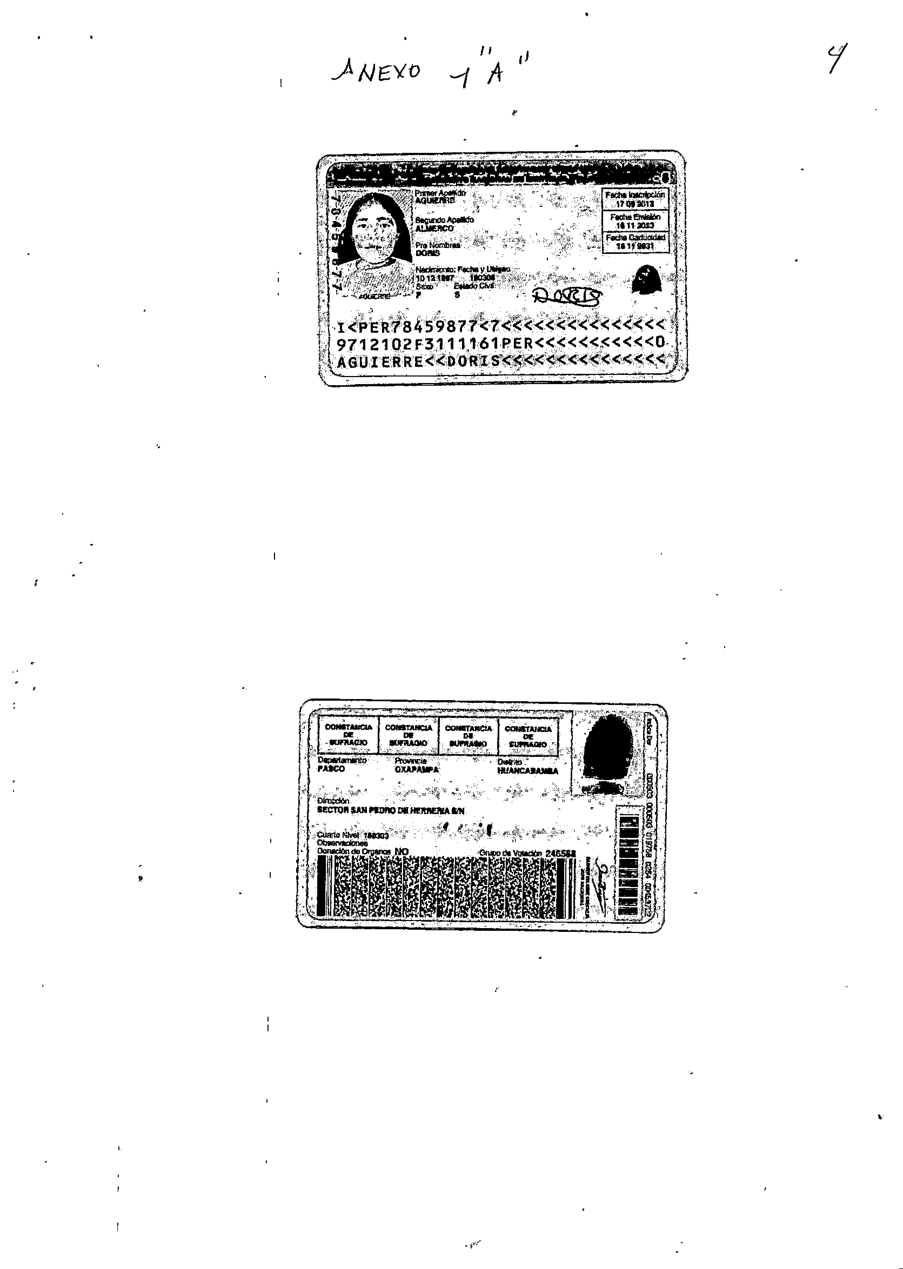

In [26]:
visualizar_pagina("CASO_001", 6)

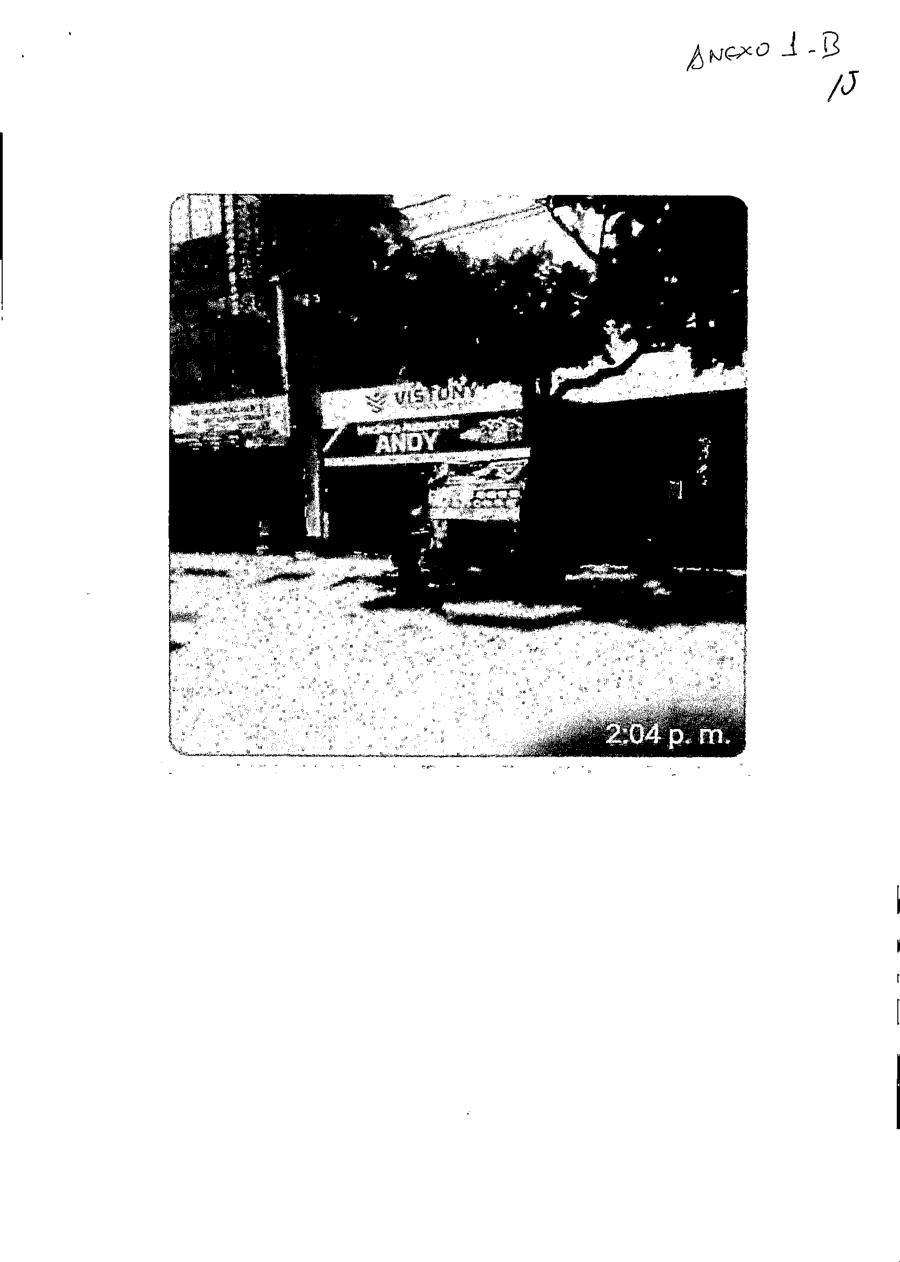

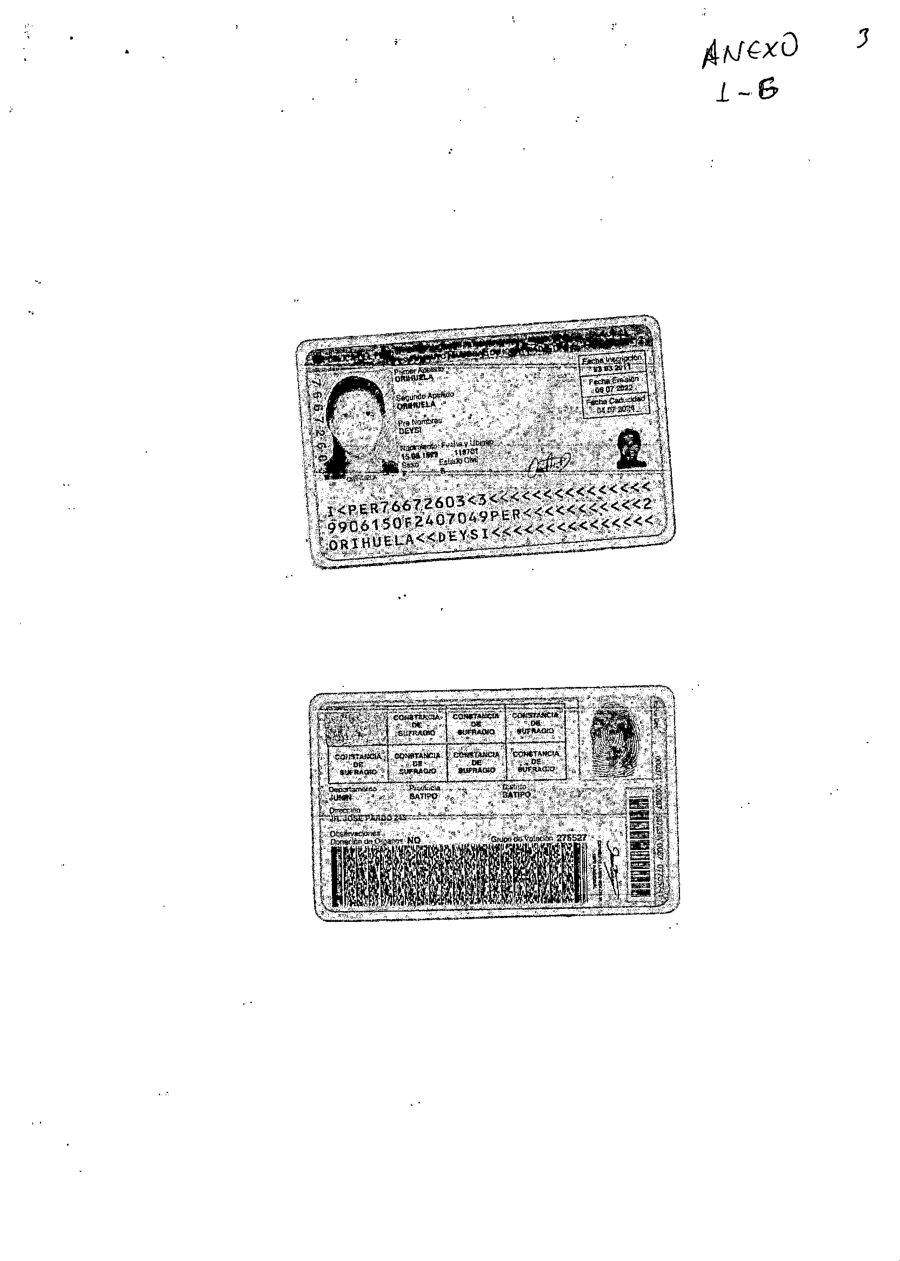

In [27]:
visualizar_pagina("CASO_002", 9)
visualizar_pagina("CASO_002", 21)

In [28]:
revision = pendientes[
    ["caso_id", "documento", "pagina", "estado", "revision_manual"]
].copy()

revision["tipo_contenido_validado"] = ""
revision["contiene_datos_personales"] = ""
revision["texto_recuperable"] = ""
revision["observaciones"] = ""

ruta_salida = (
    BASE / "data" / "processed"
    / "revision_manual_paginas_ocr.csv"
)

if not ruta_salida.exists():
    revision.to_csv(
        ruta_salida,
        index=False,
        encoding="utf-8-sig"
    )

print("Archivo de revisión:", ruta_salida)

Archivo de revisión: D:\CalificacionDemanda\data\processed\revision_manual_paginas_ocr.csv


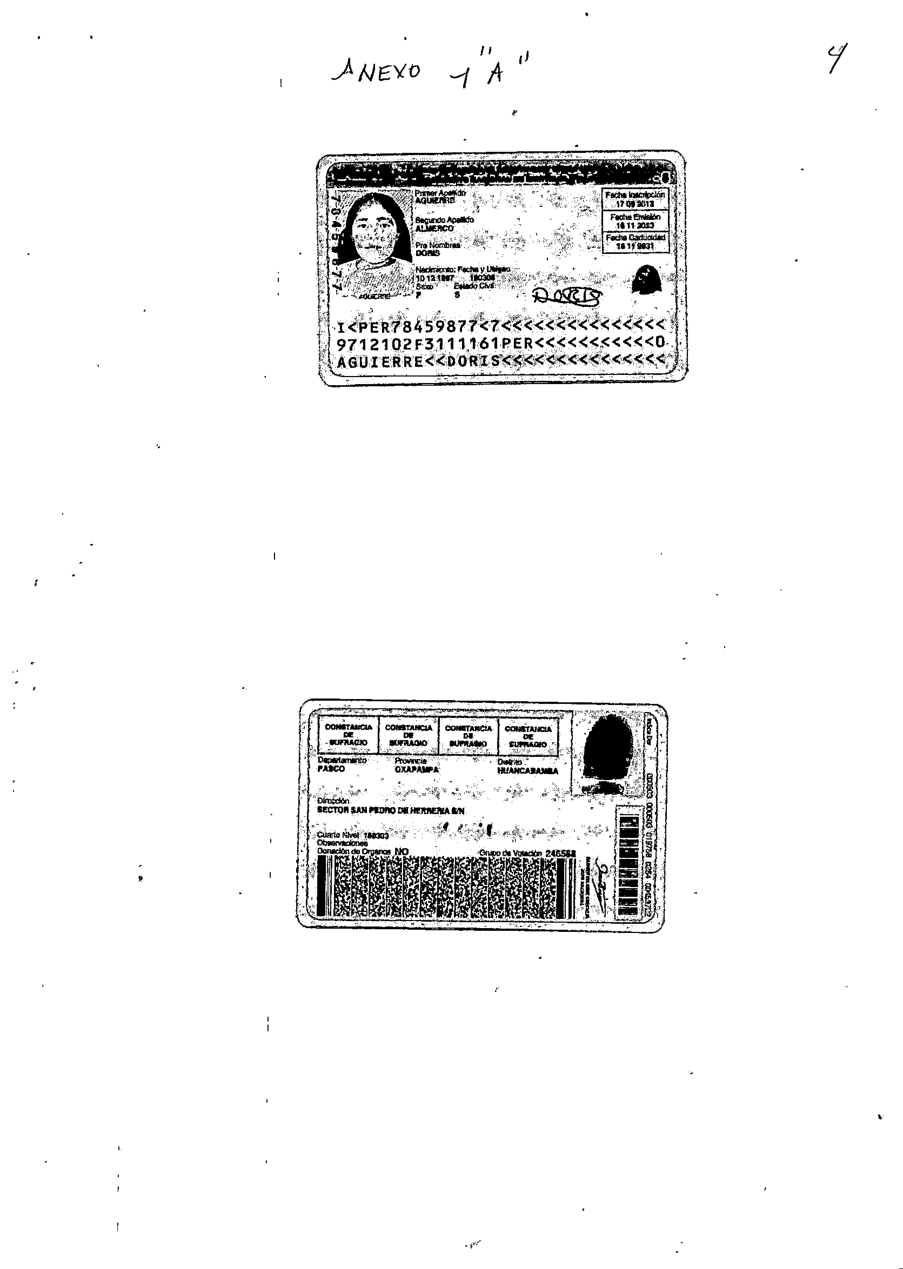

In [31]:
visualizar_pagina("CASO_001", 6)

In [ ]:
from pathlib import Path
from datetime import datetime
from io import BytesIO
import os
import shutil
import uuid

import pandas as pd
import pymupdf
import ipywidgets as widgets

from IPython.display import display, Image, clear_output

# --------------------------------------------------
# 1. CONFIGURACIÓN
# --------------------------------------------------

BASE = Path.cwd().resolve()

if BASE.name.lower() == "notebooks":
    BASE = BASE.parent

RAW = BASE / "data" / "raw"
PROCESSED = BASE / "data" / "processed"
ARCHIVO = PROCESSED / "inventario_paginas.csv"

if not ARCHIVO.is_file():
    raise FileNotFoundError(f"No existe: {ARCHIVO}")

TIPOS = [
    "DEMANDA",
    "CARATULA_EXPEDIENTE",
    "CARGO_INGRESO",
    "DNI_PADRE",
    "DNI_MADRE",
    "DNI_ALIMENTISTA",
    "ACTA_NACIMIENTO",
    "CONSTANCIA_ESTUDIOS",
    "CONSTANCIA_MEDICA",
    "CONSTANCIA_INGRESOS",
    "OTRA_CONSTANCIA",
    "BOLETA_COMPRA",
    "FACTURA",
    "RECIBO_SERVICIOS",
    "FOTOGRAFIA",
    "OTRO_ANEXO"
]

COLUMNAS = [
    "caso_id",
    "documento",
    "pagina",
    "tipo_contenido",
    "estado_revision",
    "observaciones"
]

# --------------------------------------------------
# 2. CARGAR INVENTARIO
# --------------------------------------------------

def cargar_inventario():
    df = pd.read_csv(
        ARCHIVO,
        dtype=str,
        keep_default_na=False,
        encoding="utf-8-sig"
    )

    faltantes = set(COLUMNAS) - set(df.columns)

    if faltantes:
        raise ValueError(
            f"Faltan columnas: {sorted(faltantes)}"
        )

    df["pagina"] = pd.to_numeric(
        df["pagina"], errors="coerce"
    )

    return df


inventario = cargar_inventario()

# --------------------------------------------------
# 3. LOCALIZAR PDF
# --------------------------------------------------

def localizar_documento(documento):
    relativa = Path(
        str(documento).replace("\\", "/")
    )

    if relativa.is_absolute() or ".." in relativa.parts:
        return None

    candidatos = [
        RAW / relativa,
        RAW / "documento" / relativa,
        BASE / relativa
    ]

    for ruta in candidatos:
        if ruta.is_file():
            return ruta

    return None


# --------------------------------------------------
# 4. PREPARAR PÁGINAS
# --------------------------------------------------

def obtener_pendientes():
    df = cargar_inventario()

    return (
        df[
            df["estado_revision"].str.upper()
            != "VALIDADO"
        ]
        .sort_values(
            ["caso_id", "documento", "pagina"]
        )
        .reset_index(drop=True)
    )


pendientes = obtener_pendientes()
indice_actual = 0

# --------------------------------------------------
# 5. CONTROLES
# --------------------------------------------------

titulo = widgets.HTML()

visor = widgets.Output()

selector = widgets.SelectMultiple(
    options=TIPOS,
    description="Documento:",
    rows=12,
    layout=widgets.Layout(width="420px")
)

observaciones = widgets.Textarea(
    description="Observación:",
    placeholder="Descripción breve, sin datos personales",
    layout=widgets.Layout(width="520px", height="75px")
)

btn_anterior = widgets.Button(
    description="Anterior",
    icon="arrow-left"
)

btn_siguiente = widgets.Button(
    description="Siguiente",
    icon="arrow-right"
)

btn_guardar = widgets.Button(
    description="Guardar clasificación",
    button_style="success",
    icon="save"
)

mensaje = widgets.Output()

# --------------------------------------------------
# 6. MOSTRAR PÁGINA
# --------------------------------------------------

def mostrar_pagina():
    global indice_actual, pendientes

    with visor:
        clear_output(wait=True)

        if pendientes.empty:
            titulo.value = "<b>No hay páginas pendientes.</b>"
            btn_anterior.disabled = True
            btn_siguiente.disabled = True
            btn_guardar.disabled = True
            return

        fila = pendientes.iloc[indice_actual]

        caso = fila["caso_id"]
        documento = fila["documento"]
        pagina = int(fila["pagina"])

        titulo.value = (
            f"<h3>{caso} | Página {pagina}</h3>"
            f"<p>Registro {indice_actual + 1} "
            f"de {len(pendientes)}</p>"
        )

        ruta = localizar_documento(documento)

        if ruta is None:
            print(f"No se encontró el PDF: {documento}")
            btn_guardar.disabled = True
            return

        try:
            with pymupdf.open(ruta) as pdf:

                if pagina < 1 or pagina > len(pdf):
                    print(
                        f"Página {pagina} fuera de rango. "
                        f"El PDF tiene {len(pdf)} páginas."
                    )
                    btn_guardar.disabled = True
                    return

                pix = pdf[pagina - 1].get_pixmap(
                    matrix=pymupdf.Matrix(1.3, 1.3),
                    alpha=False
                )

                display(Image(data=pix.tobytes("png")))

        except Exception as error:
            print(f"Error al abrir PDF: {error}")
            btn_guardar.disabled = True
            return

        btn_guardar.disabled = False

        anteriores = [
            x.strip()
            for x in str(
                fila["tipo_contenido"]
            ).split(";")
        ]

        selector.value = tuple(
            x for x in anteriores if x in TIPOS
        )

        observaciones.value = str(
            fila["observaciones"]
        )

    btn_anterior.disabled = indice_actual == 0
    btn_siguiente.disabled = (
        indice_actual >= len(pendientes) - 1
    )


# --------------------------------------------------
# 7. GUARDAR CLASIFICACIÓN
# --------------------------------------------------

def guardar_clasificacion(_):
    global pendientes, indice_actual

    with mensaje:
        clear_output(wait=True)

        if pendientes.empty:
            print("No hay registros pendientes.")
            return

        if not selector.value:
            print("Selecciona al menos un tipo documental.")
            return

        fila = pendientes.iloc[indice_actual]

        df = cargar_inventario()

        def normalizar_ruta(valor):
            return str(valor).replace("\\", "/").lower()

        filtro = (
            (df["caso_id"] == fila["caso_id"]) &
            (
                df["documento"].map(normalizar_ruta)
                == normalizar_ruta(fila["documento"])
            ) &
            (df["pagina"] == fila["pagina"])
        )

        if filtro.sum() != 1:
            print(
                "No se encontró una coincidencia única. "
                "No se guardaron cambios."
            )
            return

        df.loc[filtro, "tipo_contenido"] = (
            ";".join(selector.value)
        )

        df.loc[filtro, "estado_revision"] = "VALIDADO"

        df.loc[filtro, "observaciones"] = (
            observaciones.value
        )

        # Respaldo con fecha y hora
        carpeta_backup = PROCESSED / "backups"
        carpeta_backup.mkdir(exist_ok=True)

        fecha = datetime.now().strftime(
            "%Y%m%d_%H%M%S_%f"
        )

        respaldo = carpeta_backup / (
            f"inventario_paginas_{fecha}.csv"
        )

        temporal = PROCESSED / (
            f".inventario_{uuid.uuid4().hex}.tmp"
        )

        try:
            shutil.copy2(ARCHIVO, respaldo)

            df.to_csv(
                temporal,
                index=False,
                encoding="utf-8-sig"
            )

            os.replace(temporal, ARCHIVO)

        except Exception as error:
            if temporal.exists():
                temporal.unlink()

            print(f"No se pudo guardar: {error}")
            return

        print(
            f"Guardado: {fila['caso_id']} "
            f"| página {int(fila['pagina'])}"
        )

        pendientes = obtener_pendientes()

        if not pendientes.empty:
            indice_actual = min(
                indice_actual,
                len(pendientes) - 1
            )
        else:
            indice_actual = 0

        mostrar_pagina()


# --------------------------------------------------
# 8. NAVEGACIÓN
# --------------------------------------------------

def anterior(_):
    global indice_actual

    if indice_actual > 0:
        indice_actual -= 1
        mostrar_pagina()


def siguiente(_):
    global indice_actual

    if indice_actual < len(pendientes) - 1:
        indice_actual += 1
        mostrar_pagina()


btn_anterior.on_click(anterior)
btn_siguiente.on_click(siguiente)
btn_guardar.on_click(guardar_clasificacion)

# --------------------------------------------------
# 9. MOSTRAR INTERFAZ
# --------------------------------------------------

interfaz = widgets.VBox([
    titulo,
    visor,
    selector,
    observaciones,
    widgets.HBox([
        btn_anterior,
        btn_siguiente,
        btn_guardar
    ]),
    mensaje
])

display(interfaz)
mostrar_pagina()

In [30]:
inventario = pd.read_csv(
    BASE / "data" / "processed" / "inventario_paginas.csv"
)

print("ESTADO DE CLASIFICACIÓN DOCUMENTAL")

display(
    inventario["estado_revision"]
    .fillna("PENDIENTE")
    .value_counts()
)

print("\nDOCUMENTOS IDENTIFICADOS")

display(
    inventario["tipo_contenido"]
    .fillna("SIN_CLASIFICAR")
    .value_counts()
)

ESTADO DE CLASIFICACIÓN DOCUMENTAL


estado_revision
VALIDADO    141
Name: count, dtype: int64


DOCUMENTOS IDENTIFICADOS


tipo_contenido
OTRO_ANEXO             44
DEMANDA                27
ACTA_NACIMIENTO        15
DNI_MADRE               9
CARGO_INGRESO           9
BOLETA_COMPRA           9
CARATULA_EXPEDIENTE     7
FOTOGRAFIA              5
RECIBO_SERVICIOS        5
CONSTANCIA_ESTUDIOS     4
DNI_ALIMENTISTA         4
DNI_PADRE               2
OTRA_CONSTANCIA         1
Name: count, dtype: int64

In [31]:
import pandas as pd
from pathlib import Path

BASE = Path.cwd().resolve()

if BASE.name.lower() == "notebooks":
    BASE = BASE.parent

ruta = BASE / "data/processed/dataset_entrenamiento.csv"

df = pd.read_csv(ruta)

print("Total de casos:", len(df))
print("\nDistribución de etiquetas:")
display(df["etiqueta_validada"].value_counts())

print("\nValores faltantes:")
display(df.isna().sum())

Total de casos: 10

Distribución de etiquetas:


etiqueta_validada
ADMISIBLE      9
INADMISIBLE    1
Name: count, dtype: int64


Valores faltantes:


caso_id                       0
demanda_principal             0
documentos_complementarios    8
estado                        0
etiqueta_validada             0
dtype: int64

In [32]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

y = df["etiqueta_validada"].dropna()

if len(y) > 0:
    X_dummy = pd.DataFrame(
        {"constante": [1] * len(y)},
        index=y.index
    )

    baseline = DummyClassifier(
        strategy="most_frequent"
    )

    baseline.fit(X_dummy, y)

    predicciones = baseline.predict(X_dummy)

    print(
        classification_report(
            y,
            predicciones,
            zero_division=0
        )
    )

              precision    recall  f1-score   support

   ADMISIBLE       0.90      1.00      0.95         9
 INADMISIBLE       0.00      0.00      0.00         1

    accuracy                           0.90        10
   macro avg       0.45      0.50      0.47        10
weighted avg       0.81      0.90      0.85        10



In [33]:
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Se requiere un dataframe con:
# texto_demanda y etiqueta_validada

ruta_textos = (
    BASE / "data/processed/dataset_textos_ocr.csv"
)

datos = pd.read_csv(ruta_textos)

datos = datos.dropna(
    subset=["texto_demanda", "etiqueta_validada"]
).copy()

datos = datos[
    datos["texto_demanda"].astype(str).str.strip() != ""
]

conteos = datos["etiqueta_validada"].value_counts()

print("Distribución disponible:")
print(conteos)

if len(conteos) < 2:
    print(
        "Optimización no ejecutada: "
        "se requieren al menos dos clases."
    )

elif conteos.min() < 3:
    print(
        "Optimización no ejecutada: "
        "se requieren al menos tres ejemplos "
        "por clase para esta validación."
    )

else:
    X = datos["texto_demanda"].astype(str)
    y = datos["etiqueta_validada"]

    pipeline = Pipeline([
        (
            "tfidf",
            TfidfVectorizer()
        ),
        (
            "modelo",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ])

    parametros = {
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "tfidf__min_df": [1, 2],
        "modelo__C": [0.1, 1, 10]
    }

    cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid=parametros,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        error_score="raise"
    )

    busqueda.fit(X, y)

    print("Mejores hiperparámetros:")
    print(busqueda.best_params_)

    print("F1 macro promedio de validación:")
    print(busqueda.best_score_)

Distribución disponible:
etiqueta_validada
ADMISIBLE    4
Name: count, dtype: int64
Optimización no ejecutada: se requieren al menos dos clases.


## REVISAR EXPEDIENTES INADMISIBLE##

In [34]:
import pandas as pd

ruta = BASE / "data/processed/dataset_entrenamiento.csv"

casos = pd.read_csv(ruta)

display(
    casos[
        casos["etiqueta_validada"] == "INADMISIBLE"
    ][
        ["caso_id", "demanda_principal", "etiqueta_validada"]
    ]
)

,caso_id,demanda_principal,etiqueta_validada
3,CASO_005,caso_005\demanda_5.pdf,INADMISIBLE


## VERIFICAR SI TIENE TEXTO RECUPERABLE ##

In [35]:
import pymupdf

inadmisibles = casos[
    casos["etiqueta_validada"] == "INADMISIBLE"
]

for _, fila in inadmisibles.iterrows():

    ruta_pdf = localizar_pdf(
        fila["demanda_principal"]
    )

    print("Caso:", fila["caso_id"])
    print("PDF:", ruta_pdf)

    if ruta_pdf is None:
        print("No se encontró el documento.")
        continue

    with pymupdf.open(ruta_pdf) as pdf:

        texto = "\n".join(
            pagina.get_text("text")
            for pagina in pdf
        )

        print("Páginas:", len(pdf))
        print("Caracteres digitales:", len(texto.strip()))

Caso: CASO_005
PDF: D:\CalificacionDemanda\data\raw\caso_005\demanda_5.pdf
Páginas: 6
Caracteres digitales: 299
